# Café Sales Data Cleaning and Analysis (2023)

**Goal:** turn a messy record of 10,000 café sales into data a business can trust, then find out which items earn the most and where the record-keeping falls short.

**Tools:** Python (pandas, matplotlib, seaborn, scipy)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy.stats as stats

CURRENCY = "$"   # change to "₦" or another symbol if your data is in a different currency

In [2]:
df = pd.read_csv("dirty_cafe_sales.csv")   # read the raw file into a table called df
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 1. Exploratory Data Analysis

In [3]:
# number of rows and columns
df.shape

(10000, 8)

In [4]:
# column names
df.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

In [5]:
# data types and how many values are present in each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [6]:
# every distinct value in each column (except the ID and date, which have hundreds)
for column in df.columns.drop(['Transaction ID', 'Transaction Date']):
    print(f"\n{column}:")
    print(df[column].unique())


Item:
<StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str

Quantity:
<StringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str

Price Per Unit:
<StringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str

Total Spent:
<StringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',     '9.0',    '16.0',
    '15.0',    '25.0',     '8.0',     '5.0',     '3.0',     '6.0',       nan,
 'UNKNOWN',     '2.0',     '1.0',     '7.5',     '4.5',     '1.5']
Length: 20, dtype: str

Payment Method:
<StringArray>
['Credit Card', 'Cash', 'UNKNOWN', 'Digital Wallet', 'ERROR', nan]
Length: 6, dtype: str

Location:
<StringArray>
['Takeaway', 'In-store', 'UNKNOWN', nan, 'ERROR']
Length: 5, dtype: str


In [7]:
# summary statistics
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


### How much of each column is missing or invalid?
Blank cells and the placeholder words "ERROR" and "UNKNOWN" are all treated as problems.

In [8]:
problems = pd.DataFrame({
    'Blank': df.isna().sum(),
    'ERROR / UNKNOWN': df.isin(['ERROR', 'UNKNOWN']).sum(),
})
problems['Total problems'] = problems.sum(axis=1)
problems['% of rows'] = (problems['Total problems'] / len(df) * 100).round(1)
problems

,Blank,ERROR / UNKNOWN,Total problems,% of rows
Transaction ID,0,0,0,0.0
Item,333,636,969,9.7
Quantity,138,341,479,4.8
Price Per Unit,179,354,533,5.3
Total Spent,173,329,502,5.0
Payment Method,2579,599,3178,31.8
Location,3265,696,3961,39.6
Transaction Date,159,301,460,4.6


In [9]:
# duplicate rows
df.duplicated().sum()

np.int64(0)

## 2. Data Cleaning

**Approach.** Each sale must satisfy *Quantity × Price Per Unit = Total Spent*. Every menu item also has one fixed price. So instead of guessing missing numbers with an average, I rebuild them from the values that are present, then check that every row balances, the way an accountant reconciles a ledger.

In [10]:
C_sales = df.copy()

# convert number columns to numbers; 'ERROR' and 'UNKNOWN' become blanks (NaN)
for column in ['Quantity', 'Price Per Unit', 'Total Spent']:
    C_sales[column] = pd.to_numeric(C_sales[column], errors='coerce')

# convert dates; invalid dates become blanks (NaT)
C_sales['Transaction Date'] = pd.to_datetime(C_sales['Transaction Date'], errors='coerce')

# treat placeholder text as blank so it can be recovered or labelled later
for column in ['Item', 'Payment Method', 'Location']:
    C_sales[column] = C_sales[column].replace(['ERROR', 'UNKNOWN', ' ', ''], np.nan)

C_sales.dtypes

Transaction ID                 str
Item                           str
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method                 str
Location                       str
Transaction Date    datetime64[us]
dtype: object

### Step 1: confirm each item has one fixed price

In [11]:
C_sales.groupby('Item')['Price Per Unit'].unique()

Item
Cake        [3.0, nan]
Coffee      [2.0, nan]
Cookie      [1.0, nan]
Juice       [3.0, nan]
Salad       [5.0, nan]
Sandwich    [4.0, nan]
Smoothie    [4.0, nan]
Tea         [1.5, nan]
Name: Price Per Unit, dtype: object

In [12]:
menu_prices = {'Coffee': 2.0, 'Tea': 1.5, 'Cookie': 1.0, 'Cake': 3.0,
               'Juice': 3.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Salad': 5.0}

missing_before = C_sales[['Item', 'Quantity', 'Price Per Unit', 'Total Spent']].isna().sum()
missing_before

Item              969
Quantity          479
Price Per Unit    533
Total Spent       502
dtype: int64

### Step 2: recover missing numbers
- A missing price comes from the item's menu price.
- Any one missing number out of quantity, price and total is worked out from the other two.
- A missing item is recovered from its price where only one item has that price (coffee, tea, cookie, salad). Prices of 3.0 (cake or juice) and 4.0 (sandwich or smoothie) can't be resolved.

In [13]:
# price from the menu
C_sales['Price Per Unit'] = C_sales['Price Per Unit'].fillna(C_sales['Item'].map(menu_prices))

# each missing number from the other two (run twice so one recovery can enable another)
for _ in range(2):
    C_sales['Price Per Unit'] = C_sales['Price Per Unit'].fillna(C_sales['Total Spent'] / C_sales['Quantity'])
    C_sales['Quantity']       = C_sales['Quantity'].fillna(C_sales['Total Spent'] / C_sales['Price Per Unit'])
    C_sales['Total Spent']    = C_sales['Total Spent'].fillna(C_sales['Quantity'] * C_sales['Price Per Unit'])

# item from price, where the price belongs to only one item
unique_price_items = {2.0: 'Coffee', 1.5: 'Tea', 1.0: 'Cookie', 5.0: 'Salad'}
missing_item = C_sales['Item'].isna()
C_sales.loc[missing_item, 'Item'] = C_sales.loc[missing_item, 'Price Per Unit'].map(unique_price_items)

missing_after = C_sales[['Item', 'Quantity', 'Price Per Unit', 'Total Spent']].isna().sum()
pd.DataFrame({'Missing before': missing_before,
              'Missing after': missing_after,
              'Recovered': missing_before - missing_after})

,Missing before,Missing after,Recovered
Item,969,480,489
Quantity,479,23,456
Price Per Unit,533,6,527
Total Spent,502,23,479


### Step 3: remove sales that can't be recovered
A sale missing two of its three numbers can't be rebuilt without guessing, so it is removed and counted.

In [14]:
unrecoverable = C_sales[['Quantity', 'Price Per Unit', 'Total Spent']].isna().any(axis=1)
print(f"Sales that can't be recovered: {unrecoverable.sum()} ({unrecoverable.mean():.1%} of all sales)")

C_sales = C_sales[~unrecoverable].copy()
C_sales['Quantity'] = C_sales['Quantity'].astype('int64')

Sales that can't be recovered: 26 (0.3% of all sales)


### Step 4: label the text gaps clearly

In [15]:
C_sales['Item']           = C_sales['Item'].fillna('Unknown')          # price 3.0 or 4.0 with no item name
C_sales['Payment Method'] = C_sales['Payment Method'].fillna('Not Recorded')
C_sales['Location']       = C_sales['Location'].fillna('Not Recorded')

# rename the total to make its meaning clear
C_sales = C_sales.rename(columns={'Total Spent': 'Total Sales'})

for column in ['Item', 'Payment Method', 'Location']:
    print(column, C_sales[column].unique())

Item <StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'Unknown',
 'Sandwich',      'Tea',    'Juice']
Length: 9, dtype: str
Payment Method <StringArray>
['Credit Card', 'Cash', 'Not Recorded', 'Digital Wallet']
Length: 4, dtype: str
Location <StringArray>
['Takeaway', 'In-store', 'Not Recorded']
Length: 3, dtype: str


**Dates.** Missing dates are left blank rather than filled with the most common date. Filling them would pile hundreds of sales onto one day and create a false spike in the monthly trend.

In [16]:
print(f"Sales with no valid date: {C_sales['Transaction Date'].isna().sum()}")

Sales with no valid date: 460


### Step 5: reconciliation check
Every remaining sale should balance: Quantity × Price Per Unit = Total Sales. The result should be 0.

In [17]:
not_balancing = ((C_sales['Quantity'] * C_sales['Price Per Unit'] - C_sales['Total Sales']).abs() > 0.01).sum()
print(f"Sales that don't balance: {not_balancing}")
print(f"Duplicate transaction IDs: {C_sales['Transaction ID'].duplicated().sum()}")
print(f"Clean rows: {len(C_sales):,}")

Sales that don't balance: 0
Duplicate transaction IDs: 0
Clean rows: 9,974


In [18]:
C_sales.info()

<class 'pandas.DataFrame'>
Index: 9974 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9974 non-null   str           
 1   Item              9974 non-null   str           
 2   Quantity          9974 non-null   int64         
 3   Price Per Unit    9974 non-null   float64       
 4   Total Sales       9974 non-null   float64       
 5   Payment Method    9974 non-null   str           
 6   Location          9974 non-null   str           
 7   Transaction Date  9514 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 701.3 KB


In [19]:
# save the clean data
C_sales.to_csv('Clean_C_sales.csv', index=False)
C_sales.to_excel('Clean_C_sales.xlsx', index=False)

## 3. Analysis

### Key metrics

In [20]:
print(f"Total transactions: {len(C_sales):,}")
print(f"Total units sold:   {C_sales['Quantity'].sum():,}")
print(f"Revenue:            {CURRENCY}{C_sales['Total Sales'].sum():,.2f}")
print(f"Average sale:       {CURRENCY}{C_sales['Total Sales'].mean():,.2f}")

Total transactions: 9,974
Total units sold:   30,170
Revenue:            $89,042.00
Average sale:       $8.93


### Which items generate the most revenue?

In [21]:
item_summary = (C_sales.groupby('Item')
                .agg(Transactions=('Transaction ID', 'size'),
                     Units_Sold=('Quantity', 'sum'),
                     Total_Sales=('Total Sales', 'sum'),
                     Average_Sale=('Total Sales', 'mean'))
                .sort_values('Total_Sales', ascending=False))
item_summary['Share_of_Revenue'] = item_summary['Total_Sales'] / item_summary['Total_Sales'].sum()

print(item_summary.to_string(formatters={
    'Total_Sales': lambda x: f"{CURRENCY}{x:,.2f}",
    'Average_Sale': lambda x: f"{CURRENCY}{x:,.2f}",
    'Share_of_Revenue': lambda x: f"{x:.1%}"}))

          Transactions  Units_Sold Total_Sales Average_Sale Share_of_Revenue
Item                                                                        
Salad             1270        3819  $19,095.00       $15.04            21.4%
Sandwich          1127        3429  $13,716.00       $12.17            15.4%
Smoothie          1094        3336  $13,344.00       $12.20            15.0%
Juice             1168        3505  $10,515.00        $9.00            11.8%
Cake              1138        3468  $10,404.00        $9.14            11.7%
Coffee            1286        3904   $7,808.00        $6.07             8.8%
Tea               1206        3650   $5,475.00        $4.54             6.1%
Unknown            474        1461   $5,087.00       $10.73             5.7%
Cookie            1211        3598   $3,598.00        $2.97             4.0%


### Revenue by location and payment method

In [22]:
location_revenue = (C_sales.groupby('Location')['Total Sales'].sum()
                    .sort_values(ascending=False).reset_index())
location_revenue['Share'] = (location_revenue['Total Sales'] / location_revenue['Total Sales'].sum()).map('{:.1%}'.format)
location_revenue

,Location,Total Sales,Share
0,Not Recorded,35349.5,39.7%
1,In-store,27140.0,30.5%
2,Takeaway,26552.5,29.8%


In [23]:
payment_revenue = (C_sales.groupby('Payment Method')['Total Sales'].sum()
                   .sort_values(ascending=False).reset_index())
payment_revenue['Share'] = (payment_revenue['Total Sales'] / payment_revenue['Total Sales'].sum()).map('{:.1%}'.format)
payment_revenue

,Payment Method,Total Sales,Share
0,Not Recorded,27788.5,31.2%
1,Credit Card,20446.0,23.0%
2,Digital Wallet,20405.0,22.9%
3,Cash,20402.5,22.9%


## 4. Data Visualisation

### Revenue by item (bar chart)

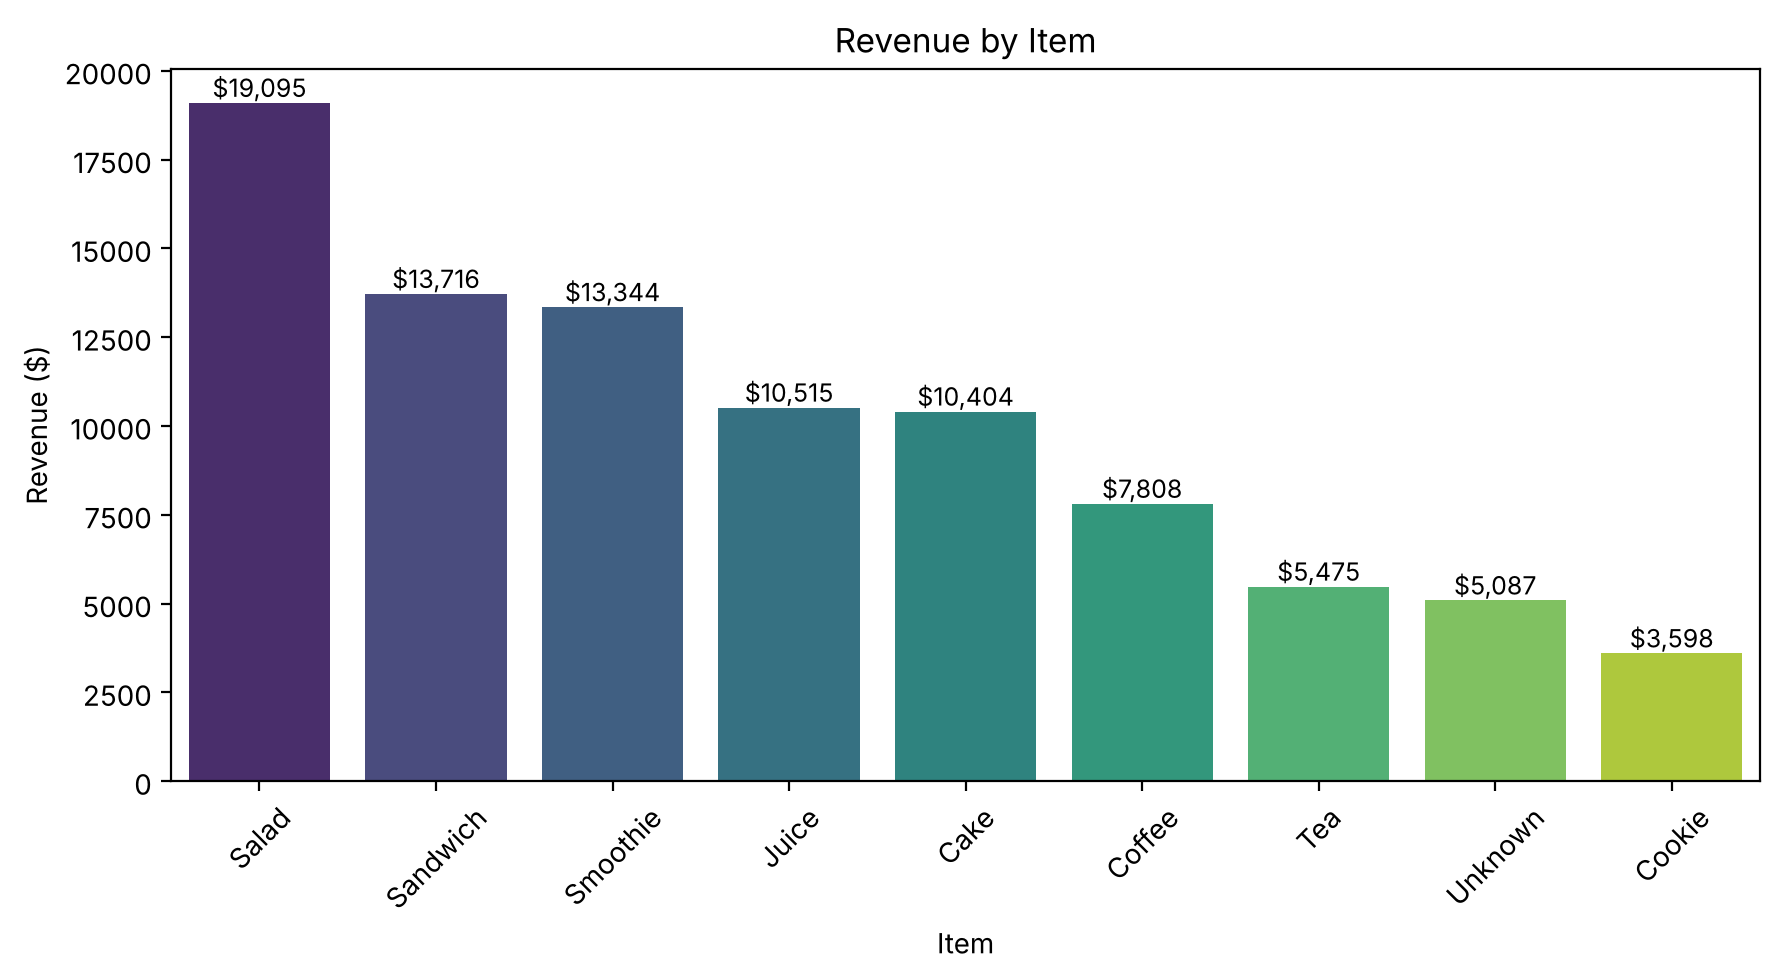

In [24]:
item_revenue = item_summary.reset_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=item_revenue, x='Item', y='Total_Sales',
                 hue='Item', palette='viridis', legend=False)

plt.title('Revenue by Item')
plt.xlabel('Item')
plt.ylabel(f'Revenue ({CURRENCY})')
plt.xticks(rotation=45)

# currency labels on top of each bar
for bar in ax.patches:
    value = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, value,
            f'{CURRENCY}{value:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Revenue by location (pie chart)

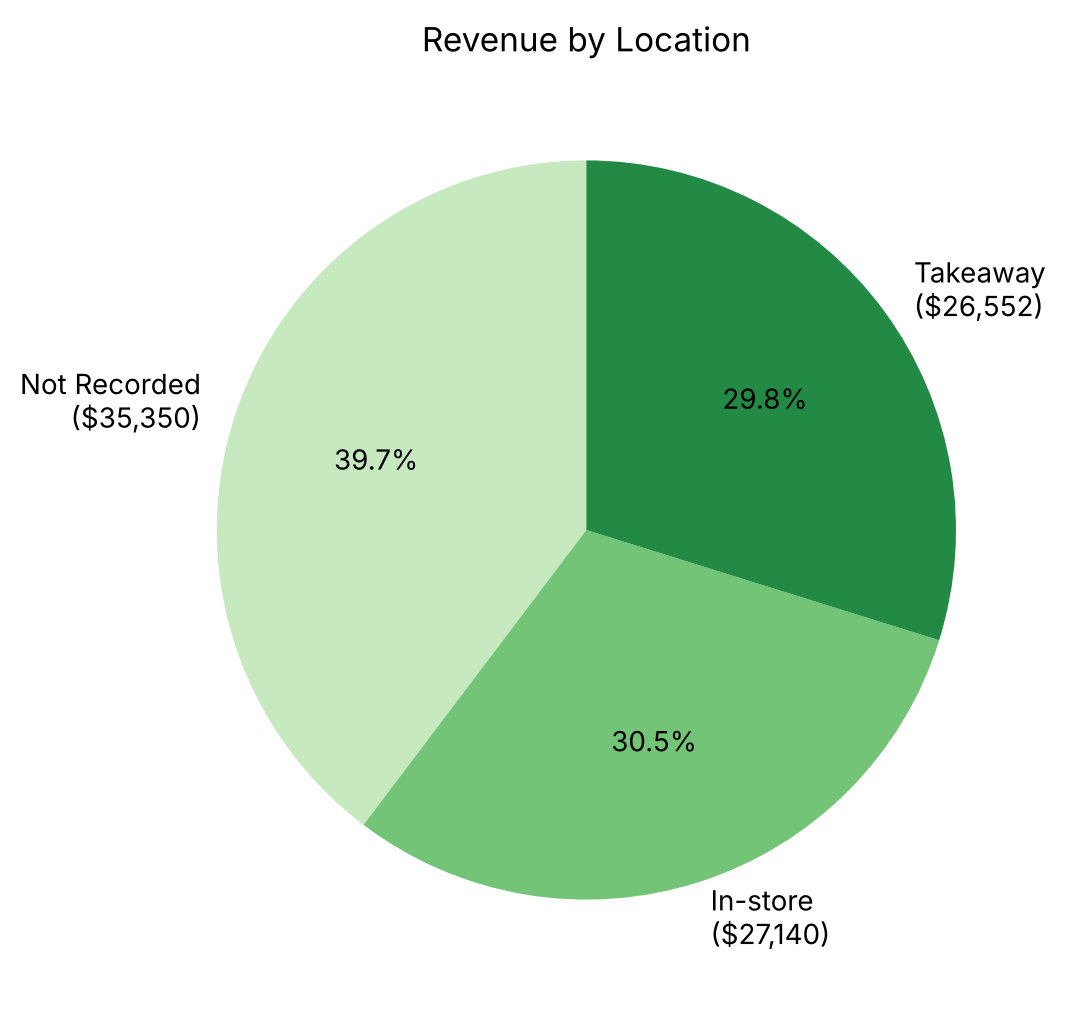

In [25]:
plt.figure(figsize=(6, 6))
colors = sns.color_palette('Greens', n_colors=len(location_revenue))

plt.pie(location_revenue['Total Sales'],
        labels=[f'{loc}\n({CURRENCY}{val:,.0f})'
                for loc, val in zip(location_revenue['Location'], location_revenue['Total Sales'])],
        autopct='%1.1f%%', startangle=90, colors=colors)
plt.title('Revenue by Location')
plt.show()

### Monthly revenue trend

In [26]:
monthly_revenue = (C_sales.dropna(subset=['Transaction Date'])     # only sales with a valid date
                   .set_index('Transaction Date')
                   .resample('MS')['Total Sales']                    # MS = month start
                   .sum()
                   .reset_index())
monthly_revenue

,Transaction Date,Total Sales
0,2023-01-01,7254.0
1,2023-02-01,6644.0
2,2023-03-01,7216.0
3,2023-04-01,7179.0
4,2023-05-01,6932.5
5,2023-06-01,7353.0
6,2023-07-01,6877.5
7,2023-08-01,7092.5
8,2023-09-01,6871.0
9,2023-10-01,7314.0


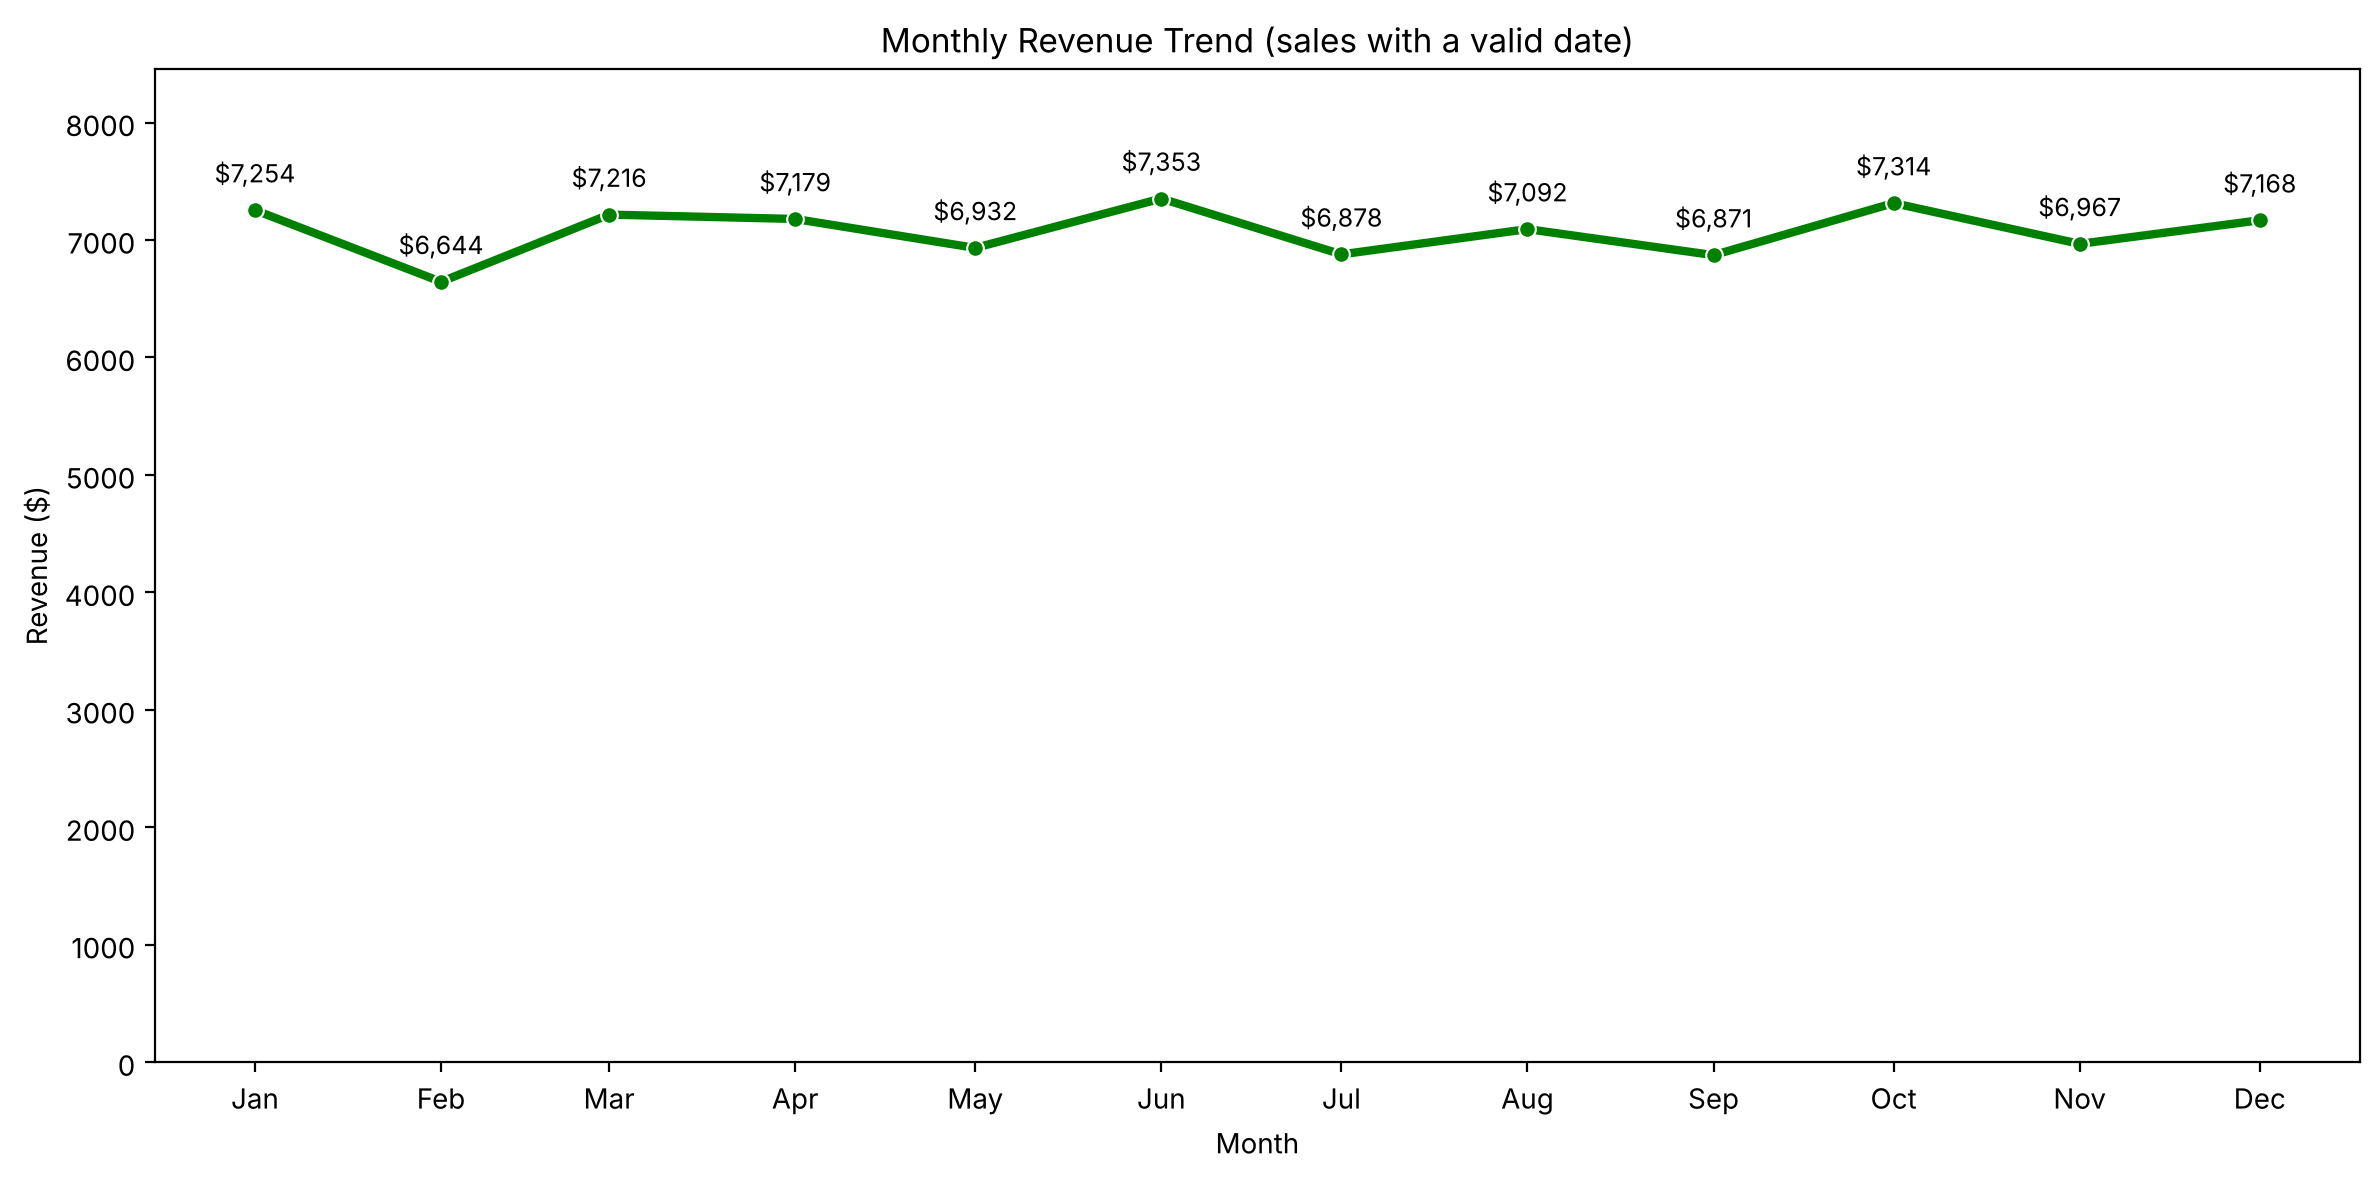

In [27]:
plt.figure(figsize=(12, 6))
xy = sns.lineplot(data=monthly_revenue, x='Transaction Date', y='Total Sales',
                  marker='o', linewidth=3, color='green')

plt.title('Monthly Revenue Trend (sales with a valid date)')
plt.xlabel('Month')
plt.ylabel(f'Revenue ({CURRENCY})')
plt.ylim(0, monthly_revenue['Total Sales'].max() * 1.15)

xy.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
xy.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

for x, y in zip(monthly_revenue['Transaction Date'], monthly_revenue['Total Sales']):
    xy.annotate(f'{CURRENCY}{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### How are sale values spread?
A histogram shows how many sales fall at each value. Most café sales are small, with a few large orders.

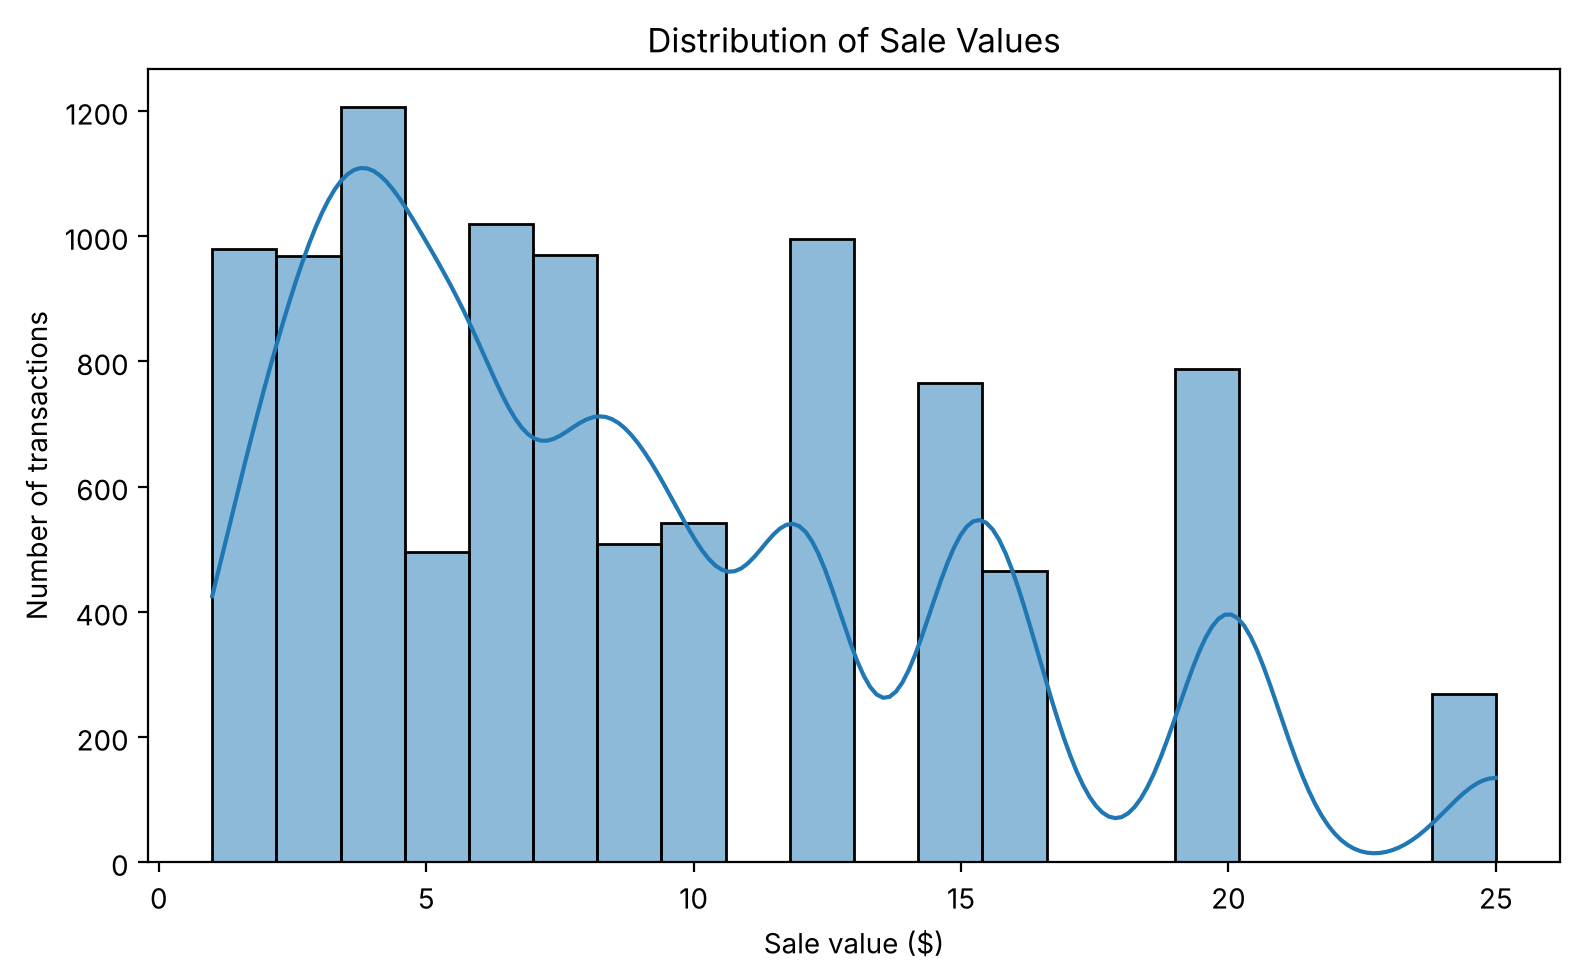

In [28]:
plt.figure(figsize=(8, 5))
sns.histplot(data=C_sales, x='Total Sales', bins=20, kde=True)   # kde adds a smooth curve
plt.title('Distribution of Sale Values')
plt.xlabel(f'Sale value ({CURRENCY})')
plt.ylabel('Number of transactions')
plt.tight_layout()
plt.show()

A Q-Q plot compares the sale values with a normal (bell-shaped) distribution. Points that bend away from the line show the values are skewed, so the median is a better "typical sale" than the average.

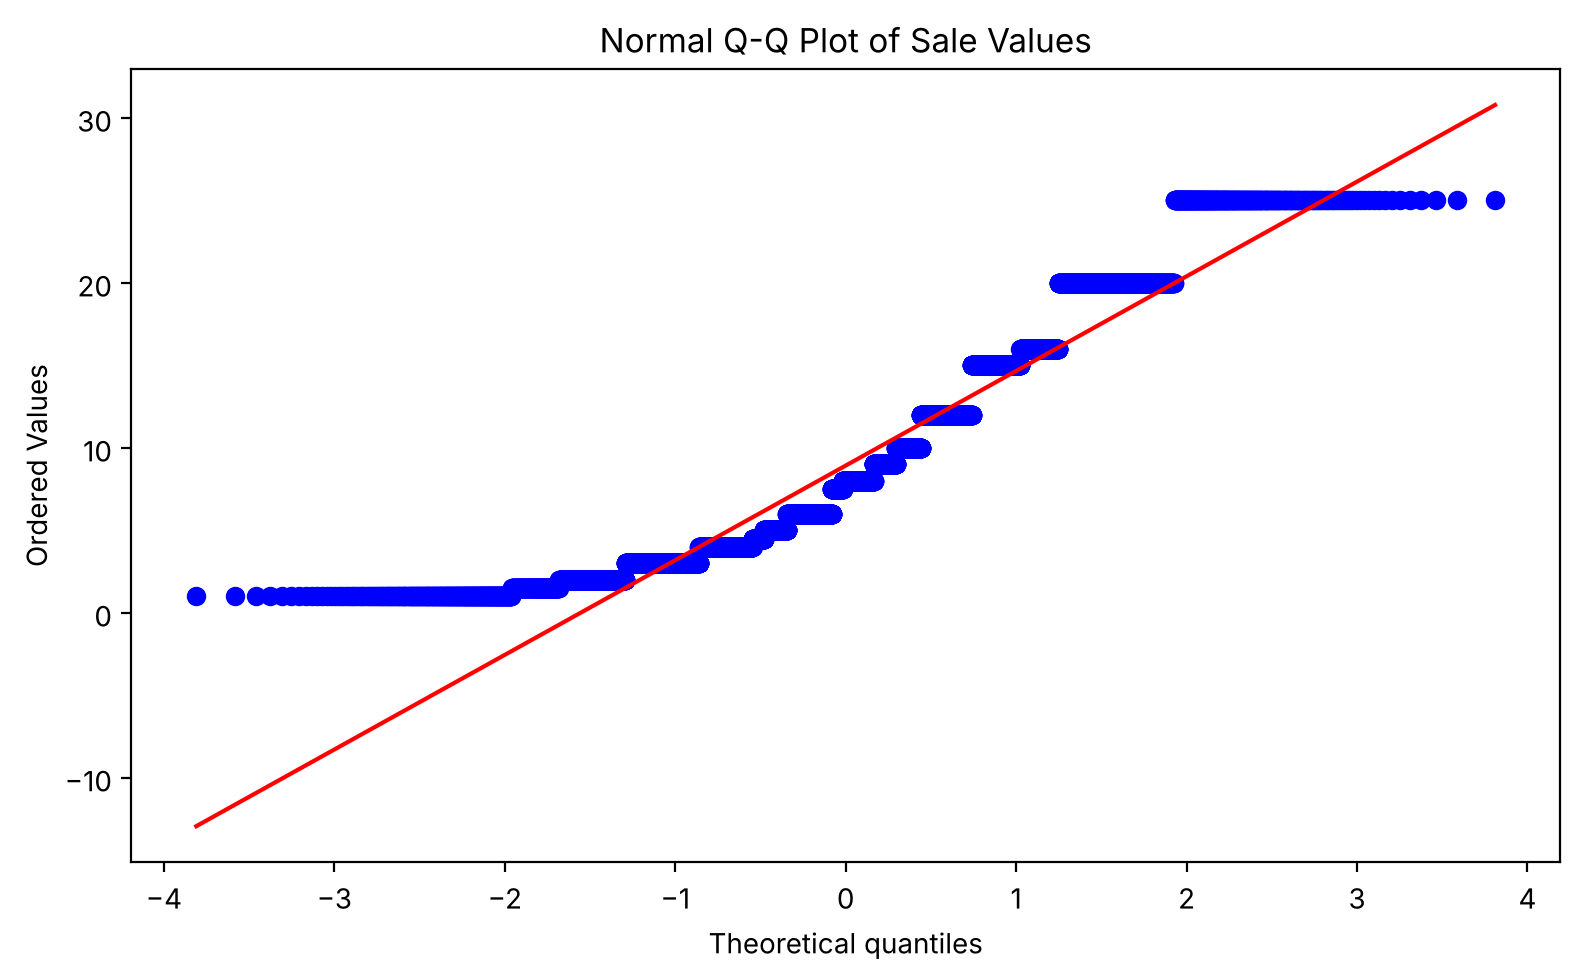

In [29]:
plt.figure(figsize=(8, 5))
stats.probplot(C_sales['Total Sales'], dist='norm', plot=plt)
plt.title('Normal Q-Q Plot of Sale Values')
plt.tight_layout()
plt.show()

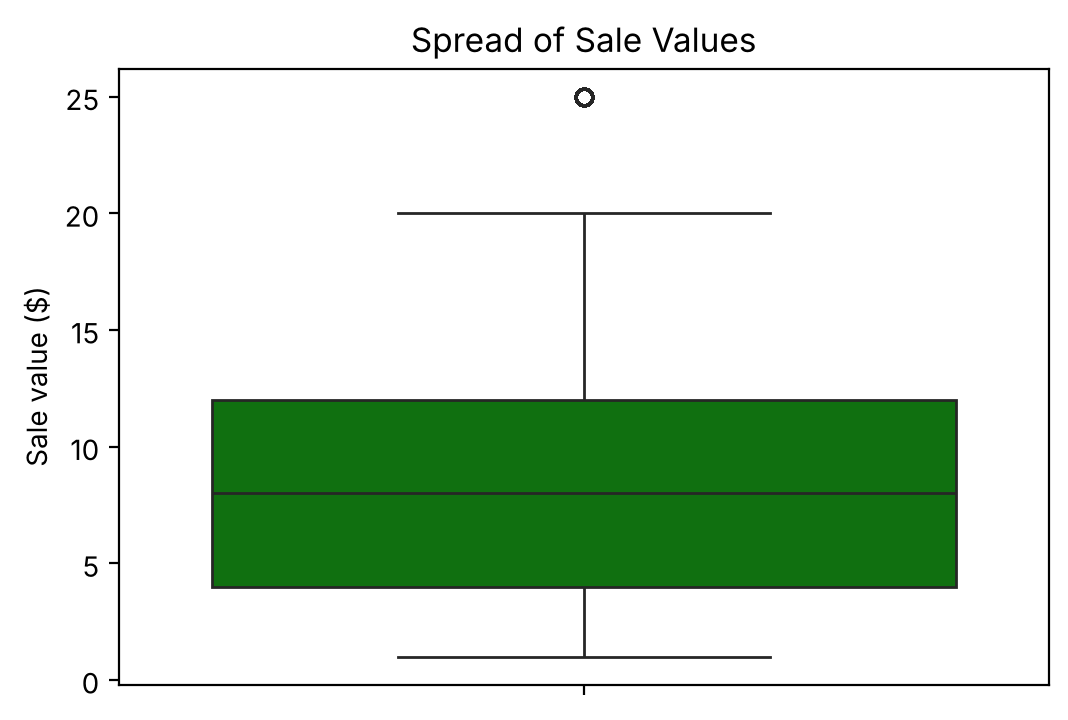

Median sale: $8.00   Average sale: $8.93


In [30]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=C_sales['Total Sales'], color='green')
plt.title('Spread of Sale Values')
plt.ylabel(f'Sale value ({CURRENCY})')
plt.show()

print(f"Median sale: {CURRENCY}{C_sales['Total Sales'].median():,.2f}   Average sale: {CURRENCY}{C_sales['Total Sales'].mean():,.2f}")